We will take a sport image where the field's lines are clearly visible. Then, we will extract these lines and plot the accumulator space for each line using Hough Transform.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [18]:
image = cv2.imread("tennis_court_2.png")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)

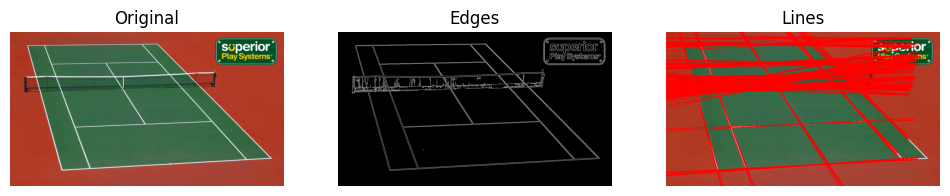

In [19]:
lines = cv2.HoughLines(edges, rho=1, theta=np.pi / 180, threshold=120)
output = image.copy()
if lines is not None:
    for rho, theta in lines[:, 0]:
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho
        pt1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * a))
        pt2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * a))
        cv2.line(output, pt1, pt2, (0, 0, 255), 2)
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); plt.title("Original"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(edges, cmap="gray"); plt.title("Edges"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB)); plt.title("Lines"); plt.axis("off")
plt.show()

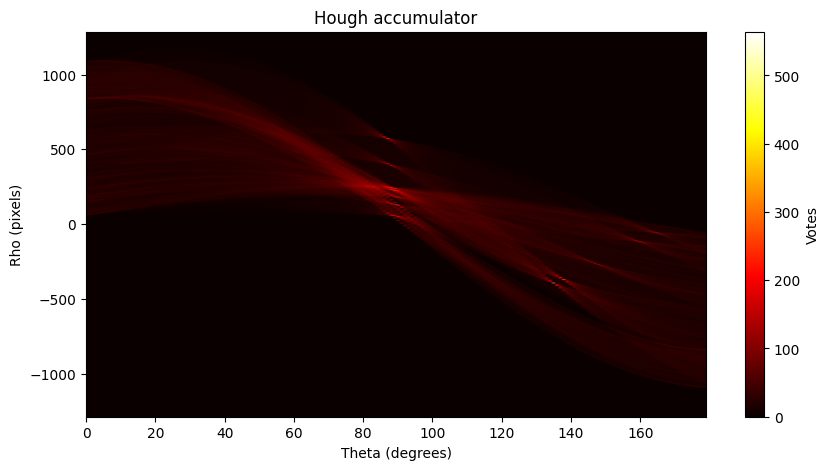

In [20]:
h, w = edges.shape
diag = int(np.ceil(np.hypot(h, w)))
accumulator = np.zeros((2 * diag, 180), dtype=np.uint32)
ys, xs = np.nonzero(edges)
for y, x in zip(ys, xs):
    for theta_deg in range(180):
        theta = np.deg2rad(theta_deg)
        rho = int(round(x * np.cos(theta) + y * np.sin(theta))) + diag
        accumulator[rho, theta_deg] += 1
plt.figure(figsize=(10, 5))
plt.imshow(accumulator, aspect="auto", origin="lower", cmap="hot",
           extent=[0, 179, -diag, diag])
plt.xlabel("Theta (degrees)")
plt.ylabel("Rho (pixels)")
plt.title("Hough accumulator")
plt.colorbar(label="Votes")
plt.show()

As can be seen, the field's line are those with the few crossings. The one in the middle with many crossings probably denote the net's lines.